# STATE — Reactome pathway-set similarity

Genes can share biological pathways even when they are different genes. The audit compared each test gene’s pathway list with the lists of training genes, then checked whether genes with more shared pathways had more accurate predictions in held-out cell types.

Run the six sections in order. Every custom calculation is written in these cells; no external analysis scripts or saved derived tables are required. The analysis uses official STATE released evaluation scores for the HVG and SE representations. The audit does not fine-tune STATE or run fresh inference.

Use Python 3.11 with `numpy==1.26.4 pandas==2.2.2 scipy==1.13.1 matplotlib==3.9.4 pyarrow==16.1.0 rdkit==2025.3.6 ipython ipykernel`. An existing raw-data cache can be selected with `STATE_PRIMARY_INPUTS`; each input is checked against its declared SHA256 before reuse.


## 1. Data source/acquisition

The source table specifies pinned score downloads, split definitions, and annotation inputs. Annotation files are distributed in a versioned public data package; their upstream providers are listed alongside the package URL. Only raw annotations are read from that package.


In [1]:
ANALYSIS_ID="state-featured/test-03"
TITLE='Reactome pathway-set similarity'

from pathlib import Path
import ast, csv, gzip, hashlib, io, json, math, os, re, shutil, tarfile, time, tomllib, urllib.request
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
STARTED=time.time()
INPUTS=Path(os.environ.get('STATE_PRIMARY_INPUTS','state_primary_inputs')).resolve()
OUTPUTS=Path('state_primary_outputs')/ANALYSIS_ID.split('/')[-1]
INPUTS.mkdir(parents=True,exist_ok=True)
OUTPUTS.mkdir(parents=True,exist_ok=True)
pd.set_option('display.max_colwidth',100)
pd.set_option('display.max_rows',100)


In [2]:
SOURCES=[{'kind': 'released_score',
  'repo': 'arcinstitute/ST-HVG-Replogle',
  'filename': 'fewshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'revision': 'bb6a9562cbbf1fd152df14cc53b4cc7517c77175',
  'path': 'scores/ST-HVG-Replogle/fewshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/fewshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'bytes': 360951,
  'sha256': '42dd8ef412843c9e0782c72d669ef352d40af63fbe7f1d11ab26b9d0f188a5e3'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-HVG-Replogle',
  'filename': 'fewshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'revision': 'bb6a9562cbbf1fd152df14cc53b4cc7517c77175',
  'path': 'scores/ST-HVG-Replogle/fewshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/fewshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'bytes': 423657,
  'sha256': 'fff2d8598e61229052483d2215809b267a9be5b28187147ea8eaa078a115280d'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-HVG-Replogle',
  'filename': 'fewshot/k562/eval_best.ckpt/k562_results.csv',
  'revision': 'bb6a9562cbbf1fd152df14cc53b4cc7517c77175',
  'path': 'scores/ST-HVG-Replogle/fewshot/k562/eval_best.ckpt/k562_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/fewshot/k562/eval_best.ckpt/k562_results.csv',
  'bytes': 368088,
  'sha256': 'c518efe5a6492b62dd3aea985e6f50ca5a8b2e9df742134041e313d2e6605ba6'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-HVG-Replogle',
  'filename': 'fewshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'revision': 'bb6a9562cbbf1fd152df14cc53b4cc7517c77175',
  'path': 'scores/ST-HVG-Replogle/fewshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/fewshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'bytes': 406063,
  'sha256': '397533d40a2efba9d75a54fca855fc39db1562ff50c765408e9afdea61826803'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-HVG-Replogle',
  'filename': 'zeroshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'revision': 'bb6a9562cbbf1fd152df14cc53b4cc7517c77175',
  'path': 'scores/ST-HVG-Replogle/zeroshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/zeroshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'bytes': 506756,
  'sha256': '0c930ad038b56c6f43d25896a15cd68e121d8902e5457718b4dfc9f163f10604'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-HVG-Replogle',
  'filename': 'zeroshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'revision': 'bb6a9562cbbf1fd152df14cc53b4cc7517c77175',
  'path': 'scores/ST-HVG-Replogle/zeroshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/zeroshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'bytes': 582103,
  'sha256': '3efc817549bbf24edd6e427fb99466f58de8fadb3a4b4335523f5cfac1bc8098'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-HVG-Replogle',
  'filename': 'zeroshot/k562/eval_best.ckpt/k562_results.csv',
  'revision': 'bb6a9562cbbf1fd152df14cc53b4cc7517c77175',
  'path': 'scores/ST-HVG-Replogle/zeroshot/k562/eval_best.ckpt/k562_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/zeroshot/k562/eval_best.ckpt/k562_results.csv',
  'bytes': 538095,
  'sha256': '8bd145c4667e03c9e367079dcfb38126e4e1f06b562f8a3fa6d1eaa1d0ba5821'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-HVG-Replogle',
  'filename': 'zeroshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'revision': 'bb6a9562cbbf1fd152df14cc53b4cc7517c77175',
  'path': 'scores/ST-HVG-Replogle/zeroshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/zeroshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'bytes': 575323,
  'sha256': 'c187b3a026c8381a84acbe5035efa30947a6774c82a6519749b1b37e85fdd14d'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-SE-Replogle',
  'filename': 'fewshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'revision': 'e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c',
  'path': 'scores/ST-SE-Replogle/fewshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/fewshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'bytes': 354986,
  'sha256': '1e4cd7df90212c61f7f171fcd5da69449e5e3edde4462201b8dedd99d07aa2c4'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-SE-Replogle',
  'filename': 'fewshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'revision': 'e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c',
  'path': 'scores/ST-SE-Replogle/fewshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/fewshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'bytes': 403167,
  'sha256': '7352c785869bf83402fb5dc79ebdbb2d911d77153c3530db4b9f143a5bec2626'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-SE-Replogle',
  'filename': 'fewshot/k562/eval_best.ckpt/k562_results.csv',
  'revision': 'e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c',
  'path': 'scores/ST-SE-Replogle/fewshot/k562/eval_best.ckpt/k562_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/fewshot/k562/eval_best.ckpt/k562_results.csv',
  'bytes': 365675,
  'sha256': 'bcba9ae671c391e78b11efda0bb0d3d48f8052541ae7599d522b293e96e3594c'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-SE-Replogle',
  'filename': 'fewshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'revision': 'e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c',
  'path': 'scores/ST-SE-Replogle/fewshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/fewshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'bytes': 411935,
  'sha256': '36b6afce7889485a2afa99a13449b59dbd06d14d564e985a37629f93101ffd34'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-SE-Replogle',
  'filename': 'zeroshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'revision': 'e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c',
  'path': 'scores/ST-SE-Replogle/zeroshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'bytes': 509894,
  'sha256': '9b7b329faa11cfdfbbac37ad571bdf47e8af7f988d61561eab51d80dce9d643a'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-SE-Replogle',
  'filename': 'zeroshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'revision': 'e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c',
  'path': 'scores/ST-SE-Replogle/zeroshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'bytes': 568100,
  'sha256': '372db67f297565e5542cac1bda688586c07e03e92a999bea953a9df812ba5317'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-SE-Replogle',
  'filename': 'zeroshot/k562/eval_best.ckpt/k562_results.csv',
  'revision': 'e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c',
  'path': 'scores/ST-SE-Replogle/zeroshot/k562/eval_best.ckpt/k562_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/k562/eval_best.ckpt/k562_results.csv',
  'bytes': 528013,
  'sha256': 'eaf22cc6169fa98ab90913366529db232ac2109fe421599f66d47b14ffd183b3'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-SE-Replogle',
  'filename': 'zeroshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'revision': 'e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c',
  'path': 'scores/ST-SE-Replogle/zeroshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'bytes': 535692,
  'sha256': 'ce7034b9e7af7255f44347ac9fdcbdd41e13b8ce674cab3c2700c0b41a1b1ffa'},
 {'kind': 'split',
  'path': 'splits/replogle_tomls/hepg2.toml',
  'url': 'https://raw.githubusercontent.com/shreyjain11/SPECTRAagent/a3b7272548095e7f3df2dabe048c953d0b6316dd/reproduction/primary/state/original/state_generalizability_20260602_single_controller/external/state/state_preprint_toml_files/replogle_tomls/hepg2.toml',
  'bytes': 9122,
  'sha256': '7f8d5df29942f7532fef09b23a0a8deec7b8339bfe7817505b977bd894813962'},
 {'kind': 'split',
  'path': 'splits/replogle_tomls/jurkat.toml',
  'url': 'https://raw.githubusercontent.com/shreyjain11/SPECTRAagent/a3b7272548095e7f3df2dabe048c953d0b6316dd/reproduction/primary/state/original/state_generalizability_20260602_single_controller/external/state/state_preprint_toml_files/replogle_tomls/jurkat.toml',
  'bytes': 10393,
  'sha256': '9606316c24dfd140bbfe7e252375c18283d4f4f10b5a4adcb463a87cd1472634'},
 {'kind': 'split',
  'path': 'splits/replogle_tomls/k562.toml',
  'url': 'https://raw.githubusercontent.com/shreyjain11/SPECTRAagent/a3b7272548095e7f3df2dabe048c953d0b6316dd/reproduction/primary/state/original/state_generalizability_20260602_single_controller/external/state/state_preprint_toml_files/replogle_tomls/k562.toml',
  'bytes': 9333,
  'sha256': 'a794ae85cacbb8ae2ce59ad5ba0fb465f5be244950b84aea28c7fa29226597c3'},
 {'kind': 'split',
  'path': 'splits/replogle_tomls/rpe1.toml',
  'url': 'https://raw.githubusercontent.com/shreyjain11/SPECTRAagent/a3b7272548095e7f3df2dabe048c953d0b6316dd/reproduction/primary/state/original/state_generalizability_20260602_single_controller/external/state/state_preprint_toml_files/replogle_tomls/rpe1.toml',
  'bytes': 10158,
  'sha256': '1681633c6b902933a8e83aae07d941ba2e63e5b968be0b80fea61a247308ecdc'}]
ANNOTATIONS=[{'path': 'annotations/Ensembl2Reactome_Homo_sapiens.txt',
  'member': 'original/state_generalizability_continued_20260603/external/Ensembl2Reactome_Homo_sapiens.txt',
  'bytes': 145040178,
  'sha256': '7bd9f04802324d18fe50431d3e8bb9fce56f64aaf0afba83b7078e9d8623e0c5',
  'source_url': 'https://reactome.org/download/current/Ensembl2Reactome_All_Levels.txt'},
 {'path': 'annotations/hgnc_complete_set.txt',
  'member': 'original/state_generalizability_continued_20260603/external/hgnc_complete_set.txt',
  'bytes': 16738373,
  'sha256': '1f8826fb0b519296233dba3f987bc38efcfb3706032ed0c0685a6936f9b11e93',
  'source_url': 'https://storage.googleapis.com/public-download-files/hgnc/tsv/tsv/hgnc_complete_set.txt'}]
ANNOTATION_PACKAGE={'path': 'annotations.tar.gz', 'url': 'https://raw.githubusercontent.com/shreyjain11/SPECTRAagent/a3b7272548095e7f3df2dabe048c953d0b6316dd/reproduction/primary/state/payloads/state-historical-annotations.tar.gz', 'bytes': 40411527, 'sha256': 'ddba844c5803aeb2e32c51f72889b16fc77efa13f1ace9ba541508f4ed31c059'}


In [3]:
def sha256_file(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda:f.read(8<<20),b''):h.update(block)
    return h.hexdigest()

def verified(path,entry):
    return path.is_file() and path.stat().st_size==entry['bytes'] and sha256_file(path)==entry['sha256']

def download(entry):
    path=INPUTS/entry['path']
    if verified(path,entry):return path
    path.parent.mkdir(parents=True,exist_ok=True)
    temporary=path.with_name(path.name+'.part')
    for attempt in range(4):
        try:
            request=urllib.request.Request(entry['url'],headers={'User-Agent':'SPECTRA-notebook/1.0'})
            with urllib.request.urlopen(request,timeout=120) as response, temporary.open('wb') as f:
                shutil.copyfileobj(response,f,8<<20)
            if not verified(temporary,entry):raise ValueError('Download checksum mismatch: '+entry['path'])
            temporary.replace(path)
            return path
        except Exception:
            if attempt==3:raise
            time.sleep(2**attempt)

with ThreadPoolExecutor(max_workers=4) as pool:
    downloaded=list(pool.map(download,SOURCES))
if ANNOTATIONS:
    missing=[s for s in ANNOTATIONS if not verified(INPUTS/s['path'],s)]
    if missing:
        archive_path=download(ANNOTATION_PACKAGE)
        with tarfile.open(archive_path) as archive:
            for entry in missing:
                path=INPUTS/entry['path'];path.parent.mkdir(parents=True,exist_ok=True)
                with archive.extractfile(entry['member']) as source,path.open('wb') as destination:
                    shutil.copyfileobj(source,destination)
                assert verified(path,entry),entry['path']
    assert all(verified(INPUTS/s['path'],s) for s in ANNOTATIONS)
source_receipts=[{'path':s['path'],'url':s['url'],'bytes':s['bytes'],'sha256':s['sha256']} for s in SOURCES]
source_receipts += [{'path':s['path'],'url':ANNOTATION_PACKAGE['url'],'source_url':s['source_url'],'bytes':s['bytes'],'sha256':s['sha256']} for s in ANNOTATIONS]
display(pd.DataFrame(source_receipts)[['path','bytes','url']])
print('Verified source files:',len(source_receipts))


,path,bytes,url
0,scores/ST-HVG-Replogle/fewshot/hepg2/eval_best.ckpt/hepg2_results.csv,360951,https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c7...
1,scores/ST-HVG-Replogle/fewshot/jurkat/eval_best.ckpt/jurkat_results.csv,423657,https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c7...
2,scores/ST-HVG-Replogle/fewshot/k562/eval_best.ckpt/k562_results.csv,368088,https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c7...
3,scores/ST-HVG-Replogle/fewshot/rpe1/eval_best.ckpt/rpe1_results.csv,406063,https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c7...
4,scores/ST-HVG-Replogle/zeroshot/hepg2/eval_best.ckpt/hepg2_results.csv,506756,https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c7...
5,scores/ST-HVG-Replogle/zeroshot/jurkat/eval_best.ckpt/jurkat_results.csv,582103,https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c7...
6,scores/ST-HVG-Replogle/zeroshot/k562/eval_best.ckpt/k562_results.csv,538095,https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c7...
7,scores/ST-HVG-Replogle/zeroshot/rpe1/eval_best.ckpt/rpe1_results.csv,575323,https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c7...
8,scores/ST-SE-Replogle/fewshot/hepg2/eval_best.ckpt/hepg2_results.csv,354986,https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d...
9,scores/ST-SE-Replogle/fewshot/jurkat/eval_best.ckpt/jurkat_results.csv,403167,https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d...


Verified source files: 22


## 2. Data processing

Parse the released condition identifiers and source filenames, retain the context/protocol/representation labels, and read the prospective annotation or chemical features. Metric values remain the official released scores.


In [4]:
def i_norm_name(x: str) -> str:
    x = str(x).strip().lower()
    x = re.sub('\\s+', ' ', x)
    return x

def i_loose_name(x: str) -> str:
    x = i_norm_name(x)
    x = re.sub('\\([^)]*\\)', '', x)
    x = re.sub('\\b(hydrochloride|hydrate|monohydrate|dihydrate|trihydrate|mesylate|maleate|tosylate|sodium|calcium|potassium|phosphate|sulfate|citrate|acetate|hemihydrate|salt|solvate|tf)\\b', '', x)
    x = re.sub('[^a-z0-9]+', '', x)
    return x

def i_parse_perturbation(value: str):
    """Parse STATE perturbation strings into name/dose/unit when possible."""
    if not isinstance(value, str):
        return (None, np.nan, None)
    s = value.strip()
    try:
        obj = ast.literal_eval(s)
        if isinstance(obj, list) and obj and isinstance(obj[0], tuple):
            tup = obj[0]
            name = str(tup[0]).strip()
            dose = float(tup[1]) if len(tup) > 1 else np.nan
            unit = str(tup[2]) if len(tup) > 2 else None
            return (name, dose, unit)
    except Exception:
        pass
    return (s, np.nan, None)

def i_parse_result_path(repo: str, path: str):
    dataset = 'unknown'
    protocol = 'unknown'
    context = None
    split_id = None
    representation = 'SE' if 'ST-SE' in repo else 'HVG'
    if 'Tahoe' in repo:
        dataset = 'Tahoe-100M'
        protocol = 'zeroshot' if path.startswith('zeroshot/') else 'fewshot'
        context = Path(path).name.replace('_results.csv', '')
    elif 'Replogle' in repo:
        dataset = 'Replogle-Nadig'
        parts = path.split('/')
        protocol = parts[0]
        context = parts[1]
    elif 'Parse' in repo:
        dataset = 'Parse-PBMC'
        parts = path.split('/')
        protocol = parts[0]
        split_id = parts[1]
        context = Path(path).name.replace('_results.csv', '')
    return (dataset, protocol, context, split_id, representation)

frames=[]
for source in SOURCES:
    if source['kind']!='released_score':continue
    frame=pd.read_csv(INPUTS/source['path'])
    dataset,protocol,context,split_id,representation=i_parse_result_path(source['repo'],source['filename'])
    for name,value in [('source_repo',source['repo']),('source_path',source['filename']),('dataset_family',dataset),('protocol',protocol),('context',context),('split_id',split_id),('representation',representation)]:frame[name]=value
    parsed=[i_parse_perturbation(x) for x in frame.perturbation]
    frame['perturbation_name']=[x[0] for x in parsed]
    frame['dose']=[x[1] for x in parsed]
    frame['dose_unit']=[x[2] for x in parsed]
    frame['perturbation_norm']=frame.perturbation_name.map(i_norm_name)
    frame['perturbation_loose']=frame.perturbation_name.map(i_loose_name)
    frames.append(frame)
results=pd.concat(frames,ignore_index=True)
results['row_key']=np.arange(len(results)).astype(str)
for metric in ['overlap_at_N','de_sig_genes_recall','pearson_delta']:
    results[metric]=pd.to_numeric(results[metric],errors='coerce')
display(results.groupby(['protocol','representation','context']).size().rename('released_rows').reset_index())


,protocol,representation,context,released_rows
0,fewshot,HVG,hepg2,945
1,fewshot,HVG,jurkat,1084
2,fewshot,HVG,k562,968
3,fewshot,HVG,rpe1,1061
4,fewshot,SE,hepg2,945
5,fewshot,SE,jurkat,1084
6,fewshot,SE,k562,968
7,fewshot,SE,rpe1,1061
8,zeroshot,HVG,hepg2,1340
9,zeroshot,HVG,jurkat,1537


In [5]:
def b_norm_symbol(x: object) -> str:
    if pd.isna(x):
        return ''
    return re.sub('\\s+', '', str(x).strip()).upper()

def b_norm_ligand(x: object) -> str:
    if pd.isna(x):
        return ''
    s = str(x).strip().lower()
    s = s.replace('_', '-')
    s = re.sub('\\s+', '-', s)
    return s

def b_load_replogle_tomls() -> dict[str, dict[str, set[str]]]:
    out: dict[str, dict[str, set[str]]] = {}
    for path in sorted((b_TOML_ROOT / 'replogle_tomls').glob('*.toml')):
        if path.name.endswith('_zeroshot.toml'):
            continue
        context = path.stem
        data = tomllib.loads(path.read_text())
        few = data.get('fewshot', {})
        key = f'replogle.{context}'
        spec = few.get(key, {})
        test = {b_norm_symbol(x) for x in spec.get('test', []) if b_norm_symbol(x)}
        val = {b_norm_symbol(x) for x in spec.get('val', []) if b_norm_symbol(x)}
        out[context] = {'test': test, 'val': val}
    return out

def b_load_parse_tomls() -> dict[str, dict[str, set[str]]]:
    out: dict[str, dict[str, set[str]]] = {}
    for path in sorted((b_TOML_ROOT / 'parse_tomls').glob('split_*.toml')):
        if path.name.endswith('_zeroshot.toml'):
            continue
        data = tomllib.loads(path.read_text())
        few = data.get('fewshot', {})
        for key, spec in few.items():
            if not key.startswith('parse.'):
                continue
            context = key.split('.', 1)[1]
            test = {b_norm_ligand(x) for x in spec.get('test', []) if b_norm_ligand(x)}
            val = {b_norm_ligand(x) for x in spec.get('val', []) if b_norm_ligand(x)}
            out[context] = {'test': test, 'val': val}
    return out

def b_split_pipe(x: object) -> list[str]:
    if pd.isna(x):
        return []
    text = str(x).strip()
    if not text:
        return []
    parts = re.split('\\|', text)
    return [p.strip() for p in parts if p.strip()]

def b_load_hgnc() -> tuple[dict[str, dict[str, object]], dict[str, str]]:
    path = b_EXT / 'hgnc_complete_set.txt'
    hgnc = pd.read_csv(path, sep='\t', dtype=str, keep_default_na=False)
    symbol_info: dict[str, dict[str, object]] = {}
    alias_to_symbol: dict[str, str] = {}
    for _, row in hgnc.iterrows():
        sym = b_norm_symbol(row.get('symbol'))
        if not sym:
            continue
        groups = b_split_pipe(row.get('gene_group'))
        ensembl = str(row.get('ensembl_gene_id', '')).strip()
        symbol_info[sym] = {'ensembl': ensembl, 'groups': set(groups), 'name': str(row.get('name', '')), 'locus_group': str(row.get('locus_group', ''))}
        alias_to_symbol[sym] = sym
        for field in ['alias_symbol', 'prev_symbol']:
            for alias in b_split_pipe(row.get(field)):
                alias_to_symbol.setdefault(b_norm_symbol(alias), sym)
    return (symbol_info, alias_to_symbol)

def b_load_reactome(symbol_info: dict[str, dict[str, object]], alias: dict[str, str]) -> dict[str, set[str]]:
    ensembl_to_symbol: dict[str, str] = {}
    for sym, info in symbol_info.items():
        ens = str(info.get('ensembl') or '').strip()
        if ens:
            ensembl_to_symbol[ens] = sym
    pathways: dict[str, set[str]] = defaultdict(set)
    path = b_EXT / 'Ensembl2Reactome_Homo_sapiens.txt'
    with path.open() as handle:
        reader = csv.reader(handle, delimiter='\t')
        for row in reader:
            if len(row) < 4:
                continue
            source, pathway, _url, name = row[:4]
            if not source.startswith('ENSG'):
                continue
            sym = ensembl_to_symbol.get(source)
            if not sym:
                continue
            pathways[sym].add(f'{pathway}:{name}')
    return pathways

b_EXT=INPUTS/'annotations'
b_TOML_ROOT=INPUTS/'splits'
b_PRIMARY_METRIC='overlap_at_N'
b_SECONDARY_METRICS=['de_sig_genes_recall','pearson_delta']
results['gene_symbol']=results.perturbation.map(b_norm_symbol)
results['ligand_norm']=results.perturbation.map(b_norm_ligand)
hgnc,aliases=b_load_hgnc()
reactome=b_load_reactome(hgnc,aliases)


## 3. Axis definition and level construction


A training-reference gene set is formed in each context from the genes in the zero-shot score inventory after subtracting the few-shot validation and test genes. Gene symbols are joined to HGNC aliases, Reactome pathway memberships and HGNC groups. Discovery contexts are HepG2 and K562; confirmation contexts are Jurkat and RPE1.


In [6]:
def b_jaccard(a: set[str], b: set[str]) -> float:
    if not a or not b:
        return 0.0
    inter = len(a & b)
    if inter == 0:
        return 0.0
    return inter / len(a | b)

def b_max_set_similarity(query_sets: dict[str, set[str]], train_genes: set[str], query_gene: str, train_index: dict[str, set[str]] | None=None) -> tuple[float, str, int]:
    qset = query_sets.get(query_gene, set())
    if not qset:
        return (0.0, '', 0)
    if train_index is None:
        candidates = train_genes
    else:
        candidates = set()
        for feature in qset:
            candidates.update(train_index.get(feature, set()))
    best = 0.0
    best_gene = ''
    for tg in candidates:
        sim = b_jaccard(qset, query_sets.get(tg, set()))
        if sim > best:
            best = sim
            best_gene = tg
    return (float(best), best_gene, len(candidates))

def b_support_stats(feature_set: set[str], feature_index: dict[str, set[str]]) -> dict[str, float]:
    if not feature_set:
        return {'n_features': 0, 'support_min': 0.0, 'support_median': 0.0, 'support_mean': 0.0, 'support_max': 0.0, 'support_log_mean': 0.0, 'supported_fraction': 0.0}
    counts = np.array([len(feature_index.get(feature, set())) for feature in feature_set], dtype=float)
    return {'n_features': int(len(feature_set)), 'support_min': float(np.min(counts)), 'support_median': float(np.median(counts)), 'support_mean': float(np.mean(counts)), 'support_max': float(np.max(counts)), 'support_log_mean': float(np.mean(np.log1p(counts))), 'supported_fraction': float(np.mean(counts > 0))}

def b_build_feature_index(feature_sets: dict[str, set[str]], train_genes: set[str]) -> dict[str, set[str]]:
    idx: dict[str, set[str]] = defaultdict(set)
    for gene in train_genes:
        for feature in feature_sets.get(gene, set()):
            idx[feature].add(gene)
    return idx

def b_infer_replogle_train_sets(df: pd.DataFrame, split_specs: dict[str, dict[str, set[str]]]) -> dict[str, set[str]]:
    all_by_context: dict[str, set[str]] = {}
    z = df[(df['dataset_family'] == 'Replogle-Nadig') & (df['protocol'] == 'zeroshot')]
    for context, sub in z.groupby('context'):
        all_by_context[str(context)] = {g for g in sub['gene_symbol'].dropna().map(b_norm_symbol) if g and g != 'NON-TARGETING'}
    train_by_context: dict[str, set[str]] = {}
    for context, genes in all_by_context.items():
        spec = split_specs.get(context, {'test': set(), 'val': set()})
        train_by_context[context] = set(genes) - set(spec.get('test', set())) - set(spec.get('val', set()))
    return train_by_context

def b_add_replogle_features(df: pd.DataFrame, hgnc_info: dict[str, dict[str, object]], alias: dict[str, str], reactome: dict[str, set[str]], split_specs: dict[str, dict[str, set[str]]]) -> tuple[pd.DataFrame, dict[str, object]]:
    sub = df[(df['dataset_family'] == 'Replogle-Nadig') & (df['protocol'] == 'fewshot')].copy()
    sub['gene_symbol'] = sub['gene_symbol'].map(lambda x: alias.get(b_norm_symbol(x), b_norm_symbol(x)))
    train_by_context = b_infer_replogle_train_sets(df, split_specs)
    group_sets: dict[str, set[str]] = {}
    pathway_sets: dict[str, set[str]] = {}
    symbol_family_sets: dict[str, set[str]] = {}
    for sym in sorted(set(sub['gene_symbol']) | set().union(*train_by_context.values())):
        canonical = alias.get(b_norm_symbol(sym), b_norm_symbol(sym))
        group_sets[canonical] = set(hgnc_info.get(canonical, {}).get('groups', set()))
        pathway_sets[canonical] = set(reactome.get(canonical, set()))
        m = re.match('^([A-Z]+)', canonical)
        prefix = m.group(1) if m else canonical
        symbol_family_sets[canonical] = {prefix[:4] if len(prefix) >= 4 else prefix}
    rows = []
    coverage = Counter()
    for context, ctx_df in sub.groupby('context'):
        train = {alias.get(b_norm_symbol(g), b_norm_symbol(g)) for g in train_by_context.get(str(context), set())}
        path_idx = b_build_feature_index(pathway_sets, train)
        group_idx = b_build_feature_index(group_sets, train)
        family_idx = b_build_feature_index(symbol_family_sets, train)
        for idx, row in ctx_df.iterrows():
            gene = alias.get(b_norm_symbol(row['gene_symbol']), b_norm_symbol(row['gene_symbol']))
            path_sim, path_gene, path_candidates = b_max_set_similarity(pathway_sets, train, gene, path_idx)
            group_sim, group_gene, group_candidates = b_max_set_similarity(group_sets, train, gene, group_idx)
            fam_sim, fam_gene, fam_candidates = b_max_set_similarity(symbol_family_sets, train, gene, family_idx)
            path_support = b_support_stats(pathway_sets.get(gene, set()), path_idx)
            group_support = b_support_stats(group_sets.get(gene, set()), group_idx)
            rows.append({'row_index': idx, 'gene_symbol_canonical': gene, 'reactome_pathway_count': len(pathway_sets.get(gene, set())), 'hgnc_group_count': len(group_sets.get(gene, set())), 'reactome_max_jaccard_to_train': path_sim, 'reactome_nearest_train_gene': path_gene, 'reactome_candidate_train_count': path_candidates, 'hgnc_group_max_jaccard_to_train': group_sim, 'hgnc_group_nearest_train_gene': group_gene, 'hgnc_group_candidate_train_count': group_candidates, 'symbol_family_match_to_train': fam_sim, 'symbol_family_nearest_train_gene': fam_gene, 'symbol_family_candidate_train_count': fam_candidates, 'reactome_pathway_train_support_min': path_support['support_min'], 'reactome_pathway_train_support_median': path_support['support_median'], 'reactome_pathway_train_support_mean': path_support['support_mean'], 'reactome_pathway_train_support_max': path_support['support_max'], 'reactome_pathway_train_support_log_mean': path_support['support_log_mean'], 'reactome_pathway_supported_fraction': path_support['supported_fraction'], 'hgnc_group_train_support_min': group_support['support_min'], 'hgnc_group_train_support_median': group_support['support_median'], 'hgnc_group_train_support_mean': group_support['support_mean'], 'hgnc_group_train_support_max': group_support['support_max'], 'hgnc_group_train_support_log_mean': group_support['support_log_mean'], 'hgnc_group_supported_fraction': group_support['supported_fraction'], 'context_train_gene_count': len(train)})
            coverage['rows'] += 1
            if pathway_sets.get(gene):
                coverage['with_reactome'] += 1
            if group_sets.get(gene):
                coverage['with_hgnc_group'] += 1
    feat = pd.DataFrame(rows).set_index('row_index')
    sub = sub.join(feat)
    return (sub, dict(coverage))

def b_assign_levels_by_cutpoints(values: pd.Series, cutpoints: list[float], labels: list[str]) -> pd.Series:

    def label(v: object) -> str:
        if pd.isna(v):
            return 'unmapped'
        fv = float(v)
        for cp, lab in zip(cutpoints, labels):
            if fv <= cp:
                return lab
        return labels[-1]
    return values.map(label)

def b_freeze_replogle_reactome_axis(features: pd.DataFrame) -> tuple[pd.DataFrame, dict[str, object]]:
    discovery_contexts = {'hepg2', 'k562'}
    confirmation_contexts = {'jurkat', 'rpe1'}
    out = features[features['gene_symbol_canonical'] != 'NON-TARGETING'].copy()
    out['spectra_subset'] = np.where(out['context'].isin(discovery_contexts), 'discovery_hepg2_k562', 'confirmation_jurkat_rpe1')
    out = out[out['context'].isin(discovery_contexts | confirmation_contexts)].copy()
    d = out[(out['spectra_subset'] == 'discovery_hepg2_k562') & (out['reactome_pathway_count'] > 0)]
    qs = d['reactome_max_jaccard_to_train'].quantile([0.33, 0.66, 0.9]).to_dict()
    cutpoints = [float(qs[0.33]), float(qs[0.66]), float(qs[0.9]), float('inf')]
    labels = ['L1_low', 'L2_mid', 'L3_high', 'L4_very_high']
    out['reactome_support_level'] = b_assign_levels_by_cutpoints(out['reactome_max_jaccard_to_train'], cutpoints, labels)
    out.loc[out['reactome_pathway_count'] <= 0, 'reactome_support_level'] = 'L0_no_annotation'
    freeze = {'axis_id': 'STATE_REPLOGLE_REACTOME_TRAIN_SUPPORT_V1', 'status': 'frozen_before_confirmation', 'unit': 'Replogle few-shot gene perturbation in a target cell context and representation', 'similarity': 'Max Jaccard overlap of Reactome pathway memberships between held-out target gene and any same-context training gene perturbation', 'direction': 'STATE performance should degrade as Reactome support level decreases', 'discovery_contexts': sorted(discovery_contexts), 'confirmation_contexts': sorted(confirmation_contexts), 'target_metric': b_PRIMARY_METRIC, 'secondary_metrics': b_SECONDARY_METRICS, 'cutpoints_from_discovery': {'<=q33': cutpoints[0], '<=q66': cutpoints[1], '<=q90': cutpoints[2], '>q90': 'L4_very_high'}, 'excluded': ['NON-TARGETING'], 'prohibited_split_features': ['target model error', 'reference-derived DE counts', 'prediction confidence', 'outcome metrics'], 'success_criteria': ['Measured similarity increases from low to high levels in discovery and confirmation', 'At least three nontrivial support levels per representation in confirmation', 'High-minus-low overlap_at_N is positive in both HVG and SE confirmation slices', 'Trend not entirely explained by one context or annotation-missing bucket']}
    return (out, freeze)

def b_quantile_cutpoints_for_axis(series: pd.Series) -> list[float]:
    values = pd.to_numeric(series, errors='coerce').dropna()
    values = values[values > 0]
    if values.nunique() < 3:
        return []
    qs = values.quantile([0.25, 0.5, 0.75]).tolist()
    cutpoints = []
    for q in qs:
        fq = float(q)
        if not cutpoints or fq > cutpoints[-1]:
            cutpoints.append(fq)
    if len(cutpoints) < 2:
        return []
    cutpoints.append(float('inf'))
    return cutpoints

def b_assign_support_bins(series: pd.Series, annotation_count: pd.Series, cutpoints: list[float]) -> pd.Series:
    labels = ['L1_low', 'L2_mid', 'L3_high', 'L4_very_high'][:len(cutpoints)]
    out = b_assign_levels_by_cutpoints(series, cutpoints, labels)
    out = out.astype(object)
    out[pd.to_numeric(annotation_count, errors='coerce').fillna(0) <= 0] = 'L0_no_annotation'
    return out

features,coverage=b_add_replogle_features(results,hgnc,aliases,reactome,b_load_replogle_tomls())
examples,axis_definition=b_freeze_replogle_reactome_axis(features)
display(coverage)


{'rows': 8116, 'with_reactome': 6640, 'with_hgnc_group': 6890}

The axis is the maximum Jaccard overlap between the target gene’s pathway set and any same-context training gene’s pathway set. Discovery quantiles 0.33, 0.66 and 0.90 define the levels; genes without annotations have a separate level.


In [7]:
FEATURE='reactome_max_jaccard_to_train'
LEVEL='reactome_support_level'
display(axis_definition['cutpoints_from_discovery'])


{'<=q33': 0.5, '<=q66': 1.0, '<=q90': 1.0, '>q90': 'L4_very_high'}

## 4. Model results or released scores

Each condition is evaluated using the official `eval_best.ckpt` result file named in section 1. `overlap_at_N` is the primary score; `de_sig_genes_recall` and `pearson_delta` are secondary scores. HVG and SE are kept separate. No audit-specific model fine-tuning is performed.


In [8]:
assert examples.row_key.notna().all()
assert 'overlap_at_N' in examples
score_columns=['source_repo','source_path','context','representation','perturbation','overlap_at_N','de_sig_genes_recall','pearson_delta']
display(examples[score_columns].head(10))
display(examples.groupby(['protocol','representation']).agg(rows=('row_key','size'),valid_overlap=('overlap_at_N','count')))


,source_repo,source_path,context,representation,perturbation,overlap_at_N,de_sig_genes_recall,pearson_delta
0,arcinstitute/ST-HVG-Replogle,fewshot/hepg2/eval_best.ckpt/hepg2_results.csv,hepg2,HVG,AAAS,0.000000,0.000000,-0.023874
1,arcinstitute/ST-HVG-Replogle,fewshot/hepg2/eval_best.ckpt/hepg2_results.csv,hepg2,HVG,AAR2,0.000000,0.153846,-0.040825
2,arcinstitute/ST-HVG-Replogle,fewshot/hepg2/eval_best.ckpt/hepg2_results.csv,hepg2,HVG,AARS,0.643678,0.659004,0.835992
3,arcinstitute/ST-HVG-Replogle,fewshot/hepg2/eval_best.ckpt/hepg2_results.csv,hepg2,HVG,ABCB7,0.214953,0.588785,0.690896
4,arcinstitute/ST-HVG-Replogle,fewshot/hepg2/eval_best.ckpt/hepg2_results.csv,hepg2,HVG,ABHD11,0.000000,0.000000,0.092514
5,arcinstitute/ST-HVG-Replogle,fewshot/hepg2/eval_best.ckpt/hepg2_results.csv,hepg2,HVG,ACTR1B,0.000000,0.000000,-0.066281
6,arcinstitute/ST-HVG-Replogle,fewshot/hepg2/eval_best.ckpt/hepg2_results.csv,hepg2,HVG,ACTR6,0.065574,0.065574,-0.003972
7,arcinstitute/ST-HVG-Replogle,fewshot/hepg2/eval_best.ckpt/hepg2_results.csv,hepg2,HVG,ACTR8,0.060150,0.060150,0.400853
8,arcinstitute/ST-HVG-Replogle,fewshot/hepg2/eval_best.ckpt/hepg2_results.csv,hepg2,HVG,ADRM1,0.000000,0.000000,0.024548
9,arcinstitute/ST-HVG-Replogle,fewshot/hepg2/eval_best.ckpt/hepg2_results.csv,hepg2,HVG,AFG3L2,0.453704,0.453704,0.648009


rows  valid_overlap
protocol representation                     
fewshot  HVG             4058           4058
         SE              4058           4058

## 5. Curves and controls

Calculate per-level means from the individual condition rows. The plots keep each representation and discovery/confirmation subset separate. Controls and contrasts below are calculated from the same rows. Higher overlap@N indicates better prediction.


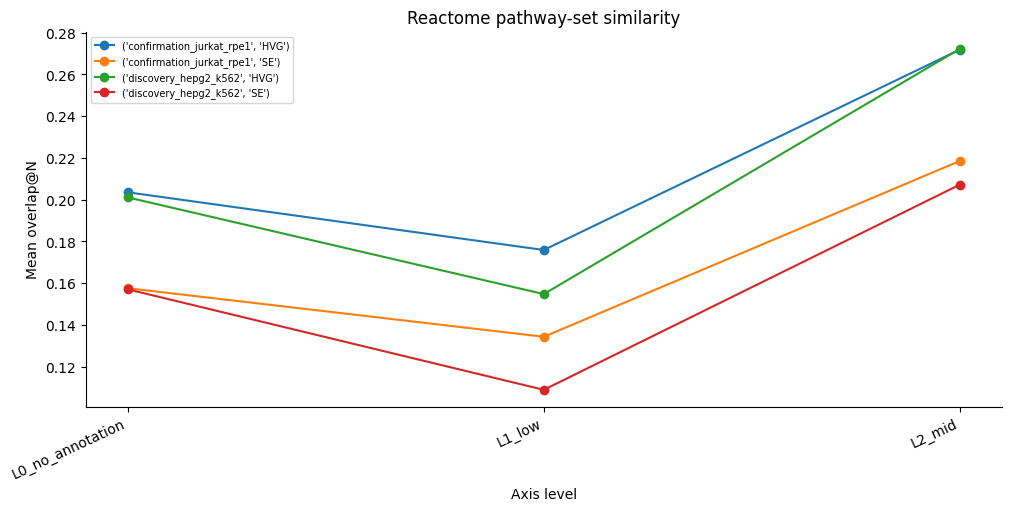

,spectra_subset,representation,level,level_order,n_rows,n_unique_contexts,n_unique_perturbations,similarity_mean,similarity_min,similarity_max,overlap_at_N_mean,overlap_at_N_median,overlap_at_N_std,de_sig_genes_recall_mean,de_sig_genes_recall_median,de_sig_genes_recall_std,pearson_delta_mean,pearson_delta_median,pearson_delta_std
0,confirmation_jurkat_rpe1,HVG,L0_no_annotation,0,392,2,275,0.000000,0.000000,0.0,0.203573,0.104409,0.218370,0.234296,0.144958,0.240826,0.393050,0.361873,0.325063
1,confirmation_jurkat_rpe1,HVG,L1_low,1,597,2,450,0.328328,0.014085,0.5,0.175928,0.114286,0.190090,0.213663,0.153061,0.222411,0.354182,0.321353,0.306058
2,confirmation_jurkat_rpe1,HVG,L2_mid,2,1156,2,871,0.898004,0.514286,1.0,0.271956,0.224353,0.235191,0.303670,0.271682,0.245809,0.489611,0.530668,0.322170
3,confirmation_jurkat_rpe1,SE,L0_no_annotation,0,392,2,275,0.000000,0.000000,0.0,0.157637,0.051688,0.202301,0.190566,0.063508,0.236688,0.341443,0.282162,0.323932
4,confirmation_jurkat_rpe1,SE,L1_low,1,597,2,450,0.328328,0.014085,0.5,0.134359,0.043478,0.183115,0.170263,0.060686,0.223729,0.302967,0.236323,0.306168
5,confirmation_jurkat_rpe1,SE,L2_mid,2,1156,2,871,0.898004,0.514286,1.0,0.218635,0.122075,0.236526,0.254532,0.152661,0.265215,0.435276,0.434444,0.329258
6,discovery_hepg2_k562,HVG,L0_no_annotation,0,346,2,247,0.000000,0.000000,0.0,0.201144,0.100578,0.230003,0.238781,0.137625,0.253945,0.345816,0.267432,0.341738
7,discovery_hepg2_k562,HVG,L1_low,1,549,2,459,0.335226,0.000000,0.5,0.154818,0.062500,0.195400,0.198119,0.093750,0.229633,0.288217,0.211965,0.288633
8,discovery_hepg2_k562,HVG,L2_mid,2,1018,2,788,0.899073,0.511628,1.0,0.272334,0.237011,0.244085,0.319637,0.307255,0.262898,0.462370,0.467261,0.324265
9,discovery_hepg2_k562,SE,L0_no_annotation,0,346,2,247,0.000000,0.000000,0.0,0.157119,0.026919,0.221400,0.198263,0.053979,0.252529,0.312483,0.191641,0.341018


,spectra_subset,representation,n_levels,n_rows,similarity_monotone_decreasing_when_order_increases,spearman_level_vs_metric,low_similarity_metric_mean,high_similarity_metric_mean,high_minus_low_metric
0,confirmation_jurkat_rpe1,HVG,3,2145,True,0.5,0.203573,0.271956,0.068382
1,confirmation_jurkat_rpe1,SE,3,2145,True,0.5,0.157637,0.218635,0.060998
2,discovery_hepg2_k562,HVG,3,1913,True,0.5,0.201144,0.272334,0.071190
3,discovery_hepg2_k562,SE,3,1913,True,0.5,0.157119,0.207293,0.050174


In [9]:
def b_safe_mean(values: pd.Series) -> float:
    values = pd.to_numeric(values, errors='coerce').dropna()
    if len(values) == 0:
        return float('nan')
    return float(values.mean())

def b_spearman_monotone(level_df: pd.DataFrame, metric: str) -> float:
    rows = level_df.dropna(subset=['level_order', metric])
    if len(rows) < 2:
        return float('nan')
    return float(rows['level_order'].corr(rows[metric], method='spearman'))

def b_summarize_levels(df: pd.DataFrame, level_col: str, sim_col: str, metrics: list[str]) -> pd.DataFrame:
    level_order = {'L0_no_annotation': 0, 'L1_low': 1, 'L2_mid': 2, 'L3_high': 3, 'L4_very_high': 4, 'no_same_family': 0, 'same_family': 1, 'unmapped': -1}
    rows = []
    for (subset, representation, level), sub in df.groupby(['spectra_subset', 'representation', level_col], dropna=False):
        row = {'spectra_subset': subset, 'representation': representation, 'level': level, 'level_order': level_order.get(str(level), float('nan')), 'n_rows': int(len(sub)), 'n_unique_contexts': int(sub['context'].nunique()), 'n_unique_perturbations': int(sub['gene_symbol_canonical'].nunique() if 'gene_symbol_canonical' in sub else sub['perturbation'].nunique()), 'similarity_mean': b_safe_mean(sub[sim_col]), 'similarity_min': float(pd.to_numeric(sub[sim_col], errors='coerce').min()), 'similarity_max': float(pd.to_numeric(sub[sim_col], errors='coerce').max())}
        for metric in metrics:
            row[f'{metric}_mean'] = b_safe_mean(sub[metric])
            row[f'{metric}_median'] = float(pd.to_numeric(sub[metric], errors='coerce').median())
            row[f'{metric}_std'] = float(pd.to_numeric(sub[metric], errors='coerce').std())
        rows.append(row)
    out = pd.DataFrame(rows)
    return out.sort_values(['spectra_subset', 'representation', 'level_order', 'level']).reset_index(drop=True)

def b_trends_from_levels(levels: pd.DataFrame, metric: str) -> pd.DataFrame:
    rows = []
    for (subset, rep), sub in levels.groupby(['spectra_subset', 'representation']):
        valid = sub[sub['level_order'] >= 0].sort_values('level_order')
        if len(valid) < 2:
            continue
        low = valid.iloc[0]
        high = valid.iloc[-1]
        rows.append({'spectra_subset': subset, 'representation': rep, 'n_levels': int(len(valid)), 'n_rows': int(valid['n_rows'].sum()), 'similarity_monotone_decreasing_when_order_increases': bool(valid['similarity_mean'].is_monotonic_increasing), 'spearman_level_vs_metric': b_spearman_monotone(valid.rename(columns={f'{metric}_mean': metric}), metric), 'low_similarity_metric_mean': float(low[f'{metric}_mean']), 'high_similarity_metric_mean': float(high[f'{metric}_mean']), 'high_minus_low_metric': float(high[f'{metric}_mean'] - low[f'{metric}_mean'])})
    return pd.DataFrame(rows)

def b_bootstrap_gap(df: pd.DataFrame, level_col: str, metric: str, low_levels: set[str], high_levels: set[str], reps: int=2000, seed: int=7) -> dict[str, float]:
    rng = np.random.default_rng(seed)
    data = df[df[level_col].isin(low_levels | high_levels)].copy()
    if data.empty:
        return {'gap_high_minus_low': float('nan'), 'ci_low': float('nan'), 'ci_high': float('nan')}
    low = data[data[level_col].isin(low_levels)][metric].dropna().to_numpy(float)
    high = data[data[level_col].isin(high_levels)][metric].dropna().to_numpy(float)
    if len(low) < 2 or len(high) < 2:
        return {'gap_high_minus_low': float('nan'), 'ci_low': float('nan'), 'ci_high': float('nan')}
    gaps = []
    for _ in range(reps):
        low_s = rng.choice(low, size=len(low), replace=True)
        high_s = rng.choice(high, size=len(high), replace=True)
        gaps.append(float(np.mean(high_s) - np.mean(low_s)))
    return {'gap_high_minus_low': float(np.mean(high) - np.mean(low)), 'ci_low': float(np.quantile(gaps, 0.025)), 'ci_high': float(np.quantile(gaps, 0.975)), 'low_n': int(len(low)), 'high_n': int(len(high))}

curve=b_summarize_levels(examples,LEVEL,FEATURE,['overlap_at_N','de_sig_genes_recall','pearson_delta'])
trends=b_trends_from_levels(curve,'overlap_at_N')

def plot_curve(table,title):
    figure,axis=plt.subplots(figsize=(10,5),layout='constrained')
    group_cols=[x for x in ['spectra_subset','representation'] if x in table]
    order=sorted(table.level.astype(str).unique())
    xmap={value:i for i,value in enumerate(order)}
    groups=table.groupby(group_cols,dropna=False) if group_cols else [('STATE',table)]
    for name,part in groups:
        part=part.copy();part['x']=part.level.astype(str).map(xmap);part=part.sort_values('x')
        axis.plot(part.x,part.overlap_at_N_mean,marker='o',label=str(name))
    axis.set_xticks(range(len(order)),order,rotation=25,ha='right')
    axis.set(xlabel='Axis level',ylabel='Mean overlap@N',title=title)
    axis.legend(fontsize=7);axis.spines[['top','right']].set_visible(False)
    figure.savefig(OUTPUTS/'curve.png',dpi=150)
    plt.show()
plot_curve(curve,TITLE)
display(curve)
display(trends)


In [10]:
context_curves=[]
for context,part in examples.groupby('context'):
    context_curves.append(b_summarize_levels(part.assign(spectra_subset=context),LEVEL,FEATURE,['overlap_at_N']))
context_curve=pd.concat(context_curves,ignore_index=True)
context_trends=b_trends_from_levels(context_curve,'overlap_at_N')
display(context_trends)
context_trends.to_csv(OUTPUTS/'context_trends.csv',index=False)


,spectra_subset,representation,n_levels,n_rows,similarity_monotone_decreasing_when_order_increases,spearman_level_vs_metric,low_similarity_metric_mean,high_similarity_metric_mean,high_minus_low_metric
0,hepg2,HVG,3,945,True,0.5,0.202897,0.293603,0.090706
1,hepg2,SE,3,945,True,0.5,0.186383,0.243243,0.056859
2,jurkat,HVG,3,1084,True,0.5,0.209996,0.247534,0.037538
3,jurkat,SE,3,1084,True,0.5,0.117517,0.133943,0.016426
4,k562,HVG,3,968,True,0.5,0.199264,0.253056,0.053792
5,k562,SE,3,968,True,0.5,0.125751,0.174709,0.048958
6,rpe1,HVG,3,1061,True,0.5,0.196238,0.297413,0.101175
7,rpe1,SE,3,1061,True,0.5,0.203457,0.306918,0.103461


In [11]:
# Tied cutpoints may leave empty levels; compare populated annotated extremes.
bootstrap_rows=[]
for (subset,representation),part in examples.groupby(['spectra_subset','representation']):
    populated=sorted(set(part[LEVEL].dropna())-{'L0_no_annotation'})
    assert len(populated)>=2,'At least two annotated levels are needed for a contrast'
    contrast=b_bootstrap_gap(part,LEVEL,'overlap_at_N',{populated[0]},{populated[-1]},reps=2000,seed=7)
    contrast.update({'low_level':populated[0],'high_level':populated[-1]})
    bootstrap_rows.append({'subset':subset,'representation':representation,**contrast})
bootstrap=pd.DataFrame(bootstrap_rows)
display(bootstrap)
bootstrap.to_csv(OUTPUTS/'bootstrap_contrasts.csv',index=False)


,subset,representation,gap_high_minus_low,ci_low,ci_high,low_n,high_n,low_level,high_level
0,confirmation_jurkat_rpe1,HVG,0.096027,0.075669,0.116034,597,1156,L1_low,L2_mid
1,confirmation_jurkat_rpe1,SE,0.084276,0.065020,0.104101,597,1156,L1_low,L2_mid
2,discovery_hepg2_k562,HVG,0.117516,0.095315,0.138392,549,1018,L1_low,L2_mid
3,discovery_hepg2_k562,SE,0.098334,0.078418,0.118068,549,1018,L1_low,L2_mid


## 6. What the agent decided, and why

The decision below follows the calculated curve and relevant controls. A positive high-minus-low support contrast means better prediction where training-reference support is higher.


In [12]:
confirmation=trends[trends.spectra_subset.str.startswith(('confirmation','zeroshot'))]
supported=len(confirmation)>=2 and (confirmation.high_minus_low_metric>0).all()
decision='Accept support-related degradation on the tested confirmation contexts' if supported else 'Reject consistent support-related degradation on the tested confirmation contexts'
print(decision)
display(confirmation[['spectra_subset','representation','high_minus_low_metric']])
print('Positive contrasts indicate better overlap at higher support; zero or negative contrasts do not support that direction.')


Accept support-related degradation on the tested confirmation contexts


,spectra_subset,representation,high_minus_low_metric
0,confirmation_jurkat_rpe1,HVG,0.068382
1,confirmation_jurkat_rpe1,SE,0.060998


Positive contrasts indicate better overlap at higher support; zero or negative contrasts do not support that direction.


In [13]:
examples.to_csv(OUTPUTS/'per_condition_results.csv',index=False)
curve.to_csv(OUTPUTS/'curve.csv',index=False)
trends.to_csv(OUTPUTS/'trends.csv',index=False)
receipt={'analysis_id':ANALYSIS_ID,'completed':True,'host':os.uname().nodename,
         'elapsed_seconds':round(time.time()-STARTED,3),'decision':decision,
         'custom_external_code_used':False,'model_inference_performed':False,
         'audit_specific_fine_tuning':False,'source_files':source_receipts,
         'rows':len(examples),'output_files':{name:sha256_file(OUTPUTS/name) for name in
             ['per_condition_results.csv','curve.csv','trends.csv','curve.png']}}
(OUTPUTS/'execution_record.json').write_text(json.dumps(receipt,indent=2,default=str)+'\n')
print('Completed:',ANALYSIS_ID,'on',receipt['host'])


Completed: state-featured/test-03 on exxact05.broadinstitute.org
